# Капилляроскопия: сравнение фотографий и классификаторов качества

**Выполненный исследовательский ноутбук · 2 ноября 2026.** Все таблицы, графики и примеры ниже получены из сохранённых результатов эксперимента. Обучение при открытии ноутбука не запускается.

Главный вопрос: можно ли отбирать пригодные для анализа сосудов кадры по резкости и похожим численным признакам, и оправдана ли отдельная нейросетевая модель по качеству и скорости?

Краткий ответ по текущим данным: четыре показателя резкости по отдельности и в комбинации ограничены. Расширенные признаки помогают строгому отбору, но пропускают часть хороших кадров. MobileNet лучше ранжирует кадры и на этом CPU быстрее расширенного расчёта 43 признаков. У каждого варианта остаются ошибки.

Содержание:
1. Критерий качества, данные и разделение пациентов.
2. Все модели: метрики, ROC/PR, ошибки и пороги.
3. Фотографии: шум, близкие значения признаков, частичная резкость, ошибки моделей.
4. ECE, калибровка, скорость и ограничения вывода.
5. Настраиваемый просмотр любого из 1000 кадров и выгрузка своего отбора.

Для пересчёта ячеек открой `.ipynb` в Jupyter или VS Code с ядром Python из этого проекта и выполни **Run All**. HTML-копия содержит готовые результаты; изменение параметров работает в ноутбуке.

## 1. Что здесь значит «хорошая фотография»

- Различимы границы и мелких, и крупных сосудов **основной сети** по всему полю.
- Частичная резкость основной сети не подходит.
- Размытые глубокие фоновые сосуды допустимы, если основная сеть чёткая.
- «Не уверен» — неуверенность оценивающего, а не отдельный обучаемый класс.

Доступно 1000 кадров: **62 согласованных `ok`, 503 согласованных `not_ok`, 435 без согласованной бинарной метки**. Только первые 565 участвуют в обучении и количественной проверке.

Одна оценка каждого кадра историческая, другая получена при перекрёстной проверке. Критерии уточнялись. Поэтому согласие здесь — рабочая разметка, а не доказанный эталон пригодности измерения сосудов.

In [1]:
from pathlib import Path
from io import BytesIO
import html, json, sys, textwrap
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from PIL import Image as PILImage
from IPython.display import display, HTML, Image as DisplayImage
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score

# Работает при запуске из корня проекта или из focus_classifier/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'focus_classifier/artifacts/gallery.json').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Открой ноутбук внутри папки проекта капилляроскопии.')
ART = ROOT / 'focus_classifier/artifacts'
PICTURES = ROOT / 'capillary_quality_1000/pictures'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from research.evaluate_calibration import calibration_bins

gallery = json.loads((ART / 'gallery.json').read_text(encoding='utf-8'))
report = json.loads((ART / 'metrics.json').read_text(encoding='utf-8'))
speed = json.loads((ART / 'speed.json').read_text(encoding='utf-8'))
folds = json.loads((ART / 'folds.json').read_text(encoding='utf-8'))
examples = json.loads((ROOT / 'focus_classifier/notebook_examples.json').read_text(encoding='utf-8'))
features = pd.read_csv(ART / 'features.csv').set_index('file')
predictions = pd.read_csv(ART / 'predictions.csv')
NAMES = {m['id']: m['name'] for m in gallery['models']}
SHORT = {'logistic_basic': '4 признака · LR', 'trees_basic': '4 признака · ExtraTrees',
         'logistic_extended': '43 признака · LR', 'trees_extended': '43 признака · ExtraTrees',
         'neural': 'MobileNet + голова'}
MAIN = list(SHORT)
df = pd.DataFrame([{k: r[k] for k in ['file','patient','fold','truth','status','human','assistant','comment']}
                   | r['features'] for r in gallery['rows']]).set_index('file')
for model in NAMES:
    by_file = predictions[predictions.model == model].set_index('file').reindex(df.index)
    df[model + '_p'] = by_file.p_ok
    df[model + '_balanced'] = by_file.predicted_balanced.eq('ok')
    df[model + '_precise'] = by_file.predicted_precise.eq('ok')
    df[model + '_threshold_balanced'] = by_file.threshold_balanced
    df[model + '_threshold_precise'] = by_file.threshold_precise
clear = df[df.truth >= 0].copy()
assert len(df) == 1000 and len(clear) == 565 and (clear.truth == 1).sum() == 62
assert predictions.shape[0] == 10000
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':10, 'axes.spines.top':False,
                     'axes.spines.right':False, 'figure.facecolor':'white'})

def showfig(fig):
    buf = BytesIO()
    fig.savefig(buf, format='png', dpi=115, bbox_inches='tight')
    plt.close(fig)
    display(DisplayImage(data=buf.getvalue()))

def accepted(model, mode='balanced', threshold=None):
    if threshold is not None:
        return df[model + '_p'] >= threshold
    return df[model + '_' + mode]

def image_path(file):
    if file not in df.index:
        raise ValueError('Файл отсутствует в эксперименте')
    return PICTURES / file

def show_photos(files, models=('trees_extended','neural'), mode='balanced', crop=None, columns=2, manual_threshold=None):
    """Сравнивает целые исходные кадры либо одинаковый участок (x,y,w,h)."""
    files = list(files)
    if not files:
        display(HTML('<p>В этом отборе нет кадров.</p>')); return
    fig, axes = plt.subplots(int(np.ceil(len(files)/columns)), columns,
                             figsize=(7.1*columns, 5.5*int(np.ceil(len(files)/columns))), squeeze=False)
    for ax, file in zip(axes.flat, files):
        row = df.loc[file]
        with PILImage.open(image_path(file)) as im:
            a = np.asarray(im.convert('RGB'))
        if crop is not None:
            x,y,w,h = crop
            a = a[y:y+h,x:x+w]
            if not a.size: raise ValueError('Участок за пределами изображения')
        ax.imshow(a, interpolation='nearest'); ax.axis('off')
        truth = 'годен' if row.truth == 1 else 'не годен' if row.truth == 0 else 'нет консенсуса'
        lines = [file, 'Согласовано: '+truth]
        for model in models:
            answer = 'годен' if accepted(model,mode,manual_threshold).loc[file] else 'не годен'
            threshold = row[model+'_threshold_'+mode] if manual_threshold is None else manual_threshold
            cutoff = 'допуск отключён' if threshold > 1 else f'порог {threshold:.3f}'
            lines.append(f'{SHORT.get(model,NAMES[model])}: P(ok)={row[model+"_p"]:.3f}, {answer}; {cutoff}')
        ax.set_title(chr(10).join(lines),fontsize=9,pad=10)
    for ax in list(axes.flat)[len(files):]: ax.axis('off')
    fig.tight_layout(); showfig(fig)

def photo_table(files):
    cols = ['truth','human','assistant','patient','fold','laplacian_raw','laplacian_smooth',
            'tenengrad_smooth','local_tenengrad_p75'] + [m+'_p' for m in MAIN]
    display(df.loc[list(files), cols].rename(columns={'truth':'консенсус: 1=годен, 0=нет, -1=спорно'}))

def pick(model='trees_extended', mode='balanced', category='accepted', n=6, offset=0,
         pool='consensus', sort='desc', threshold=None):
    base = df if pool == 'all' else clear if pool == 'consensus' else df[df.truth < 0]
    a = accepted(model,mode,threshold).reindex(base.index)
    if category == 'accepted': mask=a
    elif category == 'rejected': mask=~a
    elif category == 'false_accept': mask=a & base.truth.eq(0)
    elif category == 'false_reject': mask=~a & base.truth.eq(1)
    elif category == 'different': mask=a != accepted('neural' if model != 'neural' else 'trees_extended',mode,threshold).reindex(base.index)
    elif category == 'all': mask=pd.Series(True,index=base.index)
    else: raise ValueError('Неизвестная категория')
    result = base[mask].sort_values(model+'_p',ascending=sort=='asc')
    return result.index[offset:offset+n].tolist(), result

display(pd.DataFrame({'Количество': [len(df),len(clear),(clear.truth==1).sum(),(clear.truth==0).sum(),(df.truth<0).sum(),clear.patient.nunique()]},
                     index=['Все кадры','Согласованные','Хорошие','Плохие','Спорные / не уверен','Пациенты']))

,Количество
Все кадры,1000
Согласованные,565
Хорошие,62
Плохие,503
Спорные / не уверен,435
Пациенты,93


### Почему проверка выполнена по пациентам

В каждом видео есть близкие кадры, поэтому случайное перемешивание отдельных фотографий может завысить качество. Здесь использованы пять внешних частей по пациентам. Оцениваемый пациент исключён из обучения модели, калибровки и выбора порога. Это прогнозы **вне обучения, OOF**.

Внутри внешней обучающей части ещё три группы пациентов используются для калибровки и выбора порога. Состав частей проверяем ниже. На всех 565 кадрах отдельно обучены финальные модели для будущих изображений; их предсказания на обучающем наборе здесь не используются.

In [2]:
split_rows=[]
for fold in folds:
    train, test=set(fold['train_patients']),set(fold['test_patients'])
    assert not train & test
    tested=df[df['fold']==fold['fold']]
    assert not set(tested.patient) & train
    split_rows.append({'Часть':fold['fold']+1, 'Пациентов в проверке':len(test),
                       'Кадров в обучении':fold['train_n'], 'Хороших в обучении':fold['train_ok'],
                       'Кадров в проверке':fold['test_n'], 'Хороших в проверке':fold['test_ok']})
display(pd.DataFrame(split_rows).set_index('Часть'))
print('Пересечений пациентов нет. Все 1000 кадров имеют внешний прогноз.')

,Пациентов в проверке,Кадров в обучении,Хороших в обучении,Кадров в проверке,Хороших в проверке
Часть,,,,,
1,19,441,47,124,15
2,19,446,47,119,15
3,18,450,55,115,7
4,18,468,52,97,10
5,19,455,47,110,15


Пересечений пациентов нет. Все 1000 кадров имеют внешний прогноз.


## 2. Какие модели сравниваются

**Исходные четыре признака:** дисперсия лапласиана исходного кадра, лапласиан после Gaussian-сглаживания σ=1, средняя энергия Sobel-градиентов (Tenengrad), 75-й процентиль Tenengrad по сетке 4×4.

**43 признака:** дополнительно несколько масштабов и процентилей локального фокуса, неравномерность фокуса, оценка шума, контраст, яркость, доля засветки и ориентационная структура градиентов. Они не являются маской сосудов и могут реагировать на другие текстуры.

**Обучение:** отдельные логистические регрессии для каждого исходного признака; LR и ExtraTrees для 4 и 43 признаков. Параметры фиксированы, поиск гиперпараметров не проводился.

**Отдельная нейросетевая модель:** фиксированный MobileNetV3 Small с весами ImageNet, весь кадр 512×384 без обрезки, 576 выходных признаков и обученная регуляризованная линейная голова. Основные слои сети на этой выборке не дообучались.

**AUROC** оценивает порядок ранжирования: выше ли вероятность у хорошего кадра, чем у плохого. **AP** оценивает поиск редких хороших кадров. **Precision** — доля хороших среди принятых. **Recall** — доля найденных хороших от всех 62. ECE рассмотрим отдельно.

In [3]:
metrics_rows=[]
for model, result in report['models'].items():
    c,d=result['calibrated'],result['balanced']
    ci=result['ci95']['auroc']
    metrics_rows.append({'Модель':NAMES[model], 'AUROC':c['auroc'], '95% интервал AUROC':f'{ci[0]:.3f}–{ci[1]:.3f}',
                         'AP':c['average_precision'], 'Accuracy':d['accuracy'], 'Balanced accuracy':d['balanced_accuracy'],
                         'Годных среди принятых':d['precision_ok'], 'Найдено хороших':d['tp'],
                         'Допущено плохих':d['fp'], 'Потеряно хороших':d['fn']})
display(pd.DataFrame(metrics_rows).set_index('Модель').round(3))

,AUROC,95% интервал AUROC,AP,Accuracy,Balanced accuracy,Годных среди принятых,Найдено хороших,Допущено плохих,Потеряно хороших
Модель,,,,,,,,,
Всегда не годен,0.429,0.350–0.510,0.094,0.890,0.500,NaN,0,0,62
Лапласиан исходный,0.475,0.387–0.560,0.100,0.522,0.534,0.123,34,242,28
Лапласиан после сглаживания,0.381,0.308–0.464,0.084,0.540,0.508,0.113,29,227,33
Tenengrad всего кадра,0.627,0.561–0.697,0.138,0.565,0.685,0.181,52,236,10
Локальный Tenengrad p75,0.664,0.597–0.731,0.154,0.563,0.691,0.182,53,238,9
Логистическая регрессия · 4 признака,0.880,0.835–0.924,0.468,0.796,0.822,0.333,53,106,9
ExtraTrees · 4 признака,0.875,0.816–0.925,0.503,0.835,0.794,0.374,46,77,16
Логистическая регрессия · 43 признаков,0.960,0.943–0.977,0.718,0.897,0.893,0.519,55,51,7
ExtraTrees · 43 признаков,0.960,0.940–0.978,0.789,0.871,0.899,0.457,58,69,4


**Как читать таблицу.** Обычный режим выбирает порог по максимуму balanced accuracy на внутренних пациентах: чувствительность к хорошим и плохим классам получает равный вес. Это не режим гарантированной чистоты отбора.

Константа «всегда не годен» даёт **89% accuracy**, но не находит ни одного хорошего кадра. Её вероятность — доля хороших в соответствующей обучающей части, поэтому объединённый AUROC может отличаться от 0,5: сама частота слегка различается по частям. Это служебный ориентир, а не полезный отбор.

Интервалы построены 1000 перевыборками целых пациентов при фиксированных внешних прогнозах. Они не включают вариабельность повторного обучения и выбора семейства модели.

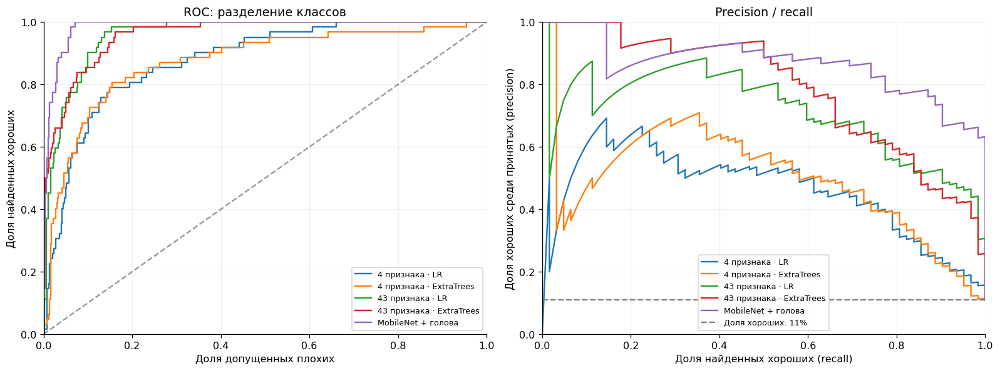

In [4]:
fig,axes=plt.subplots(1,2,figsize=(14,5.3))
y=clear.truth.to_numpy()
for model in MAIN:
    p=clear[model+'_p'].to_numpy()
    fpr,tpr,_=roc_curve(y,p)
    precision,recall,_=precision_recall_curve(y,p)
    axes[0].plot(fpr,tpr,label=SHORT[model])
    axes[1].plot(recall,precision,label=SHORT[model])
axes[0].plot([0,1],[0,1],'k--',alpha=.4)
axes[1].axhline(y.mean(),color='gray',ls='--',label='Доля хороших: 11%')
axes[0].set(xlabel='Доля допущенных плохих',ylabel='Доля найденных хороших',title='ROC: разделение классов',xlim=(0,1),ylim=(0,1))
axes[1].set(xlabel='Доля найденных хороших (recall)',ylabel='Доля хороших среди принятых (precision)',title='Precision / recall',xlim=(0,1),ylim=(0,1))
for ax in axes: ax.grid(alpha=.2); ax.legend(fontsize=8)
fig.tight_layout();showfig(fig)

### Обычный и строгий режимы отбора

В строгом режиме порог выбирается на внутренних пациентах так, чтобы получить precision не ниже 90% при хотя бы пяти принятых кадрах и сохранить максимально возможное число хороших. Если такой порог не найден, допуск отключён. Внешние результаты показывают, сохранилось ли качество на других пациентах.

У ExtraTrees на 43 признаках принято **29 хороших + 3 плохих**, сохранилось 47% хороших. У нейросети — **34 хороших + 7 плохих**, сохранилось 55%. Само по себе лучшее ранжирование не гарантирует лучшую precision у конкретного автоматически выбранного порога.

Принято  Хороших  Плохих  Precision  \
Режим          Модель                                                          
Баланс классов 4 признака · LR               159       53     106      0.333   
               4 признака · ExtraTrees       123       46      77      0.374   
               43 признака · LR              106       55      51      0.519   
               43 признака · ExtraTrees      127       58      69      0.457   
               MobileNet + голова             93       59      34      0.634   
Строгий отбор  4 признака · LR                 0        0       0        NaN   
               4 признака · ExtraTrees         0        0       0        NaN   
               43 признака · LR                8        6       2      0.750   
               43 признака · ExtraTrees       32       29       3      0.906   
               MobileNet + голова             41       34       7      0.829   

                                         Recall  Потеряно хороших  
Режим          Модель                                              
Баланс классов 4 признака · LR            0.855                 9  
               4 признака · ExtraTrees    0.742                16  
               43 признака · LR           0.887                 7  
               43 признака · ExtraTrees   0.935                 4  
               MobileNet + голова         0.952                 3  
Строгий отбор  4 признака · LR            0.000                62  
               4 признака · ExtraTrees    0.000                62  
               43 признака · LR           0.097                56  
               43 признака · ExtraTrees   0.468                33  
               MobileNet + голова         0.548                28

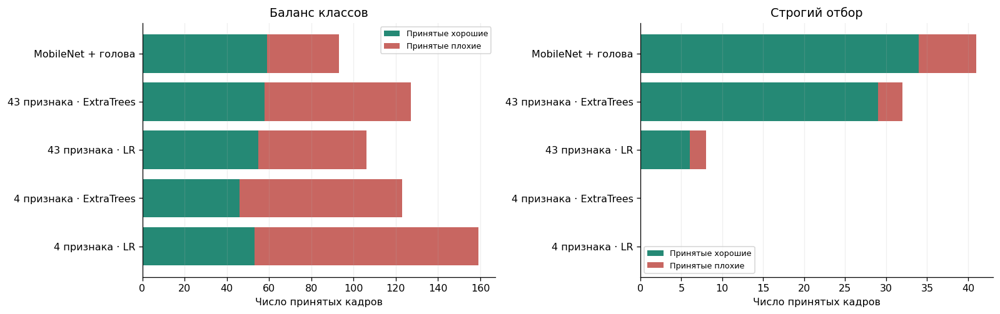

In [5]:
mode_rows=[]
for mode,title in [('balanced','Баланс классов'),('precise','Строгий отбор')]:
    for model in MAIN:
        d=report['models'][model][mode]
        mode_rows.append({'Режим':title,'Модель':SHORT[model], 'Принято':d['accepted'],
                          'Хороших':d['tp'],'Плохих':d['fp'],'Precision':d['precision_ok'],
                          'Recall':d['recall_ok'],'Потеряно хороших':d['fn']})
display(pd.DataFrame(mode_rows).set_index(['Режим','Модель']).round(3))
fig,axes=plt.subplots(1,2,figsize=(14,4.5))
for ax,(mode,title) in zip(axes,[('balanced','Баланс классов'),('precise','Строгий отбор')]):
    good=[report['models'][m][mode]['tp'] for m in MAIN]
    bad=[report['models'][m][mode]['fp'] for m in MAIN]
    ax.barh(range(len(MAIN)),good,color='#258975',label='Принятые хорошие')
    ax.barh(range(len(MAIN)),bad,left=good,color='#c86661',label='Принятые плохие')
    ax.set(yticks=range(len(MAIN)),yticklabels=[SHORT[m] for m in MAIN],xlabel='Число принятых кадров',title=title)
    ax.legend(fontsize=8);ax.grid(axis='x',alpha=.2)
fig.tight_layout();showfig(fig)

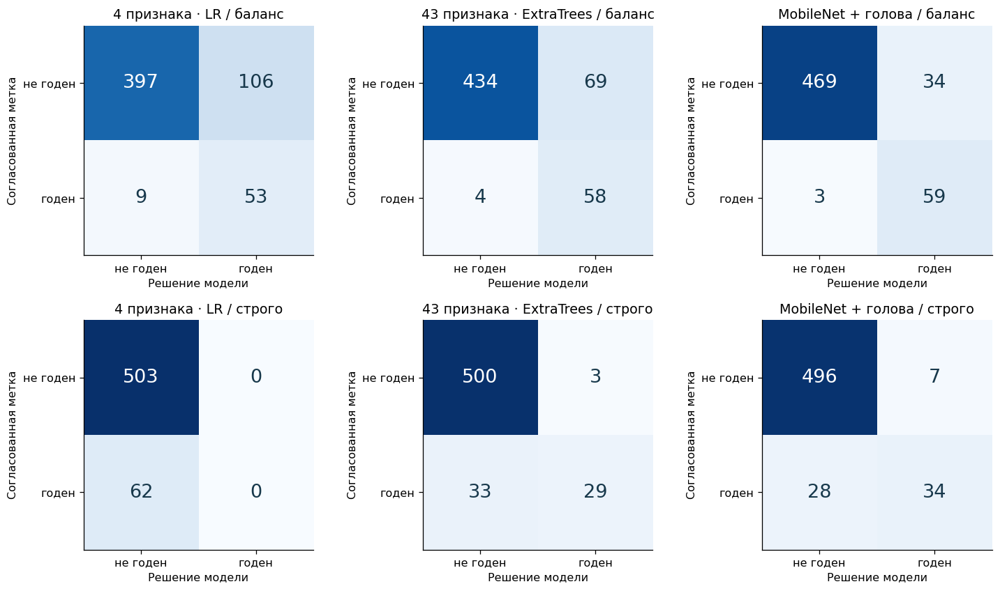

In [6]:
fig,axes=plt.subplots(2,3,figsize=(13,7.5))
for row,mode in enumerate(['balanced','precise']):
    for col,model in enumerate(['logistic_basic','trees_extended','neural']):
        d=report['models'][model][mode]
        cm=np.array([[d['tn'],d['fp']],[d['fn'],d['tp']]])
        ax=axes[row,col];ax.imshow(cm,cmap='Blues',vmin=0,vmax=503)
        for i in range(2):
            for j in range(2): ax.text(j,i,str(cm[i,j]),ha='center',va='center',color='white' if cm[i,j]>250 else '#17384b',fontsize=17)
        ax.set(xticks=[0,1],xticklabels=['не годен','годен'],yticks=[0,1],yticklabels=['не годен','годен'],
               xlabel='Решение модели',ylabel='Согласованная метка',title=SHORT[model]+' / '+('баланс' if mode=='balanced' else 'строго'))
fig.tight_layout();showfig(fig)

## 3. Что видно на самих фотографиях

Ниже — выбранные по заранее указанным правилам иллюстрации, а не дополнительная оценочная выборка. На каждой фотографии подписаны согласованная метка, внешняя вероятность `P(ok)`, решение и порог своей проверочной части. В основном режиме у разных частей пороги различаются.

Для чтения границ мелких сосудов уменьшенной иллюстрации недостаточно: в отдельной ячейке ниже есть полноразмерное изображение и одинаковые участки кадров. Исходные PNG не изменяются.

### 3.1. Шум может давать «высокую резкость»

Слева — согласованный хороший кадр с наибольшей оценкой нейросети; справа — согласованный плохой с максимальной дисперсией лапласиана. На правом кадре видна сильная зернистость, а границы сосудов не различимы. Лапласиан реагирует на быстрые перепады яркости, поэтому высокая величина ещё не означает чёткие сосуды.

Это наблюдение объясняет конкретный контрпример простому правилу «больше лапласиан → лучше». Оно не является доказательством механизма каждого решения обученной модели.

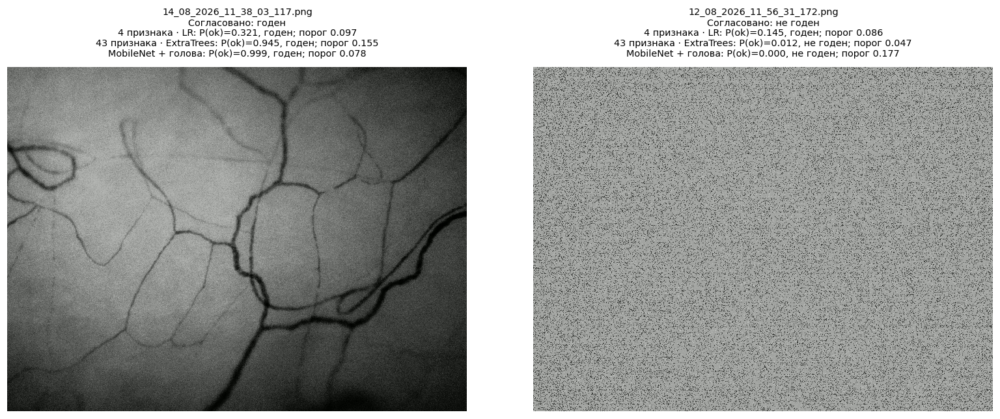

,"консенсус: 1=годен, 0=нет, -1=спорно",human,assistant,patient,fold,laplacian_raw,laplacian_smooth,tenengrad_smooth,local_tenengrad_p75,logistic_basic_p,trees_basic_p,logistic_extended_p,trees_extended_p,neural_p
file,,,,,,,,,,,,,,
14_08_2026_11_38_03_117.png,1,ok,ok,14446,0,0.028551,0.000185,0.009861,0.013115,0.321392,0.647375,0.944592,0.944941,0.999004
12_08_2026_11_56_31_172.png,0,not_ok,not_ok,14408,4,0.405704,0.002308,0.054504,0.055702,0.144719,0.033197,0.000068,0.012070,0.000149


In [7]:
noise_pair=examples['good']+examples['bad_high_laplacian']
show_photos(noise_pair,models=('logistic_basic','trees_extended','neural'))
photo_table(noise_pair)

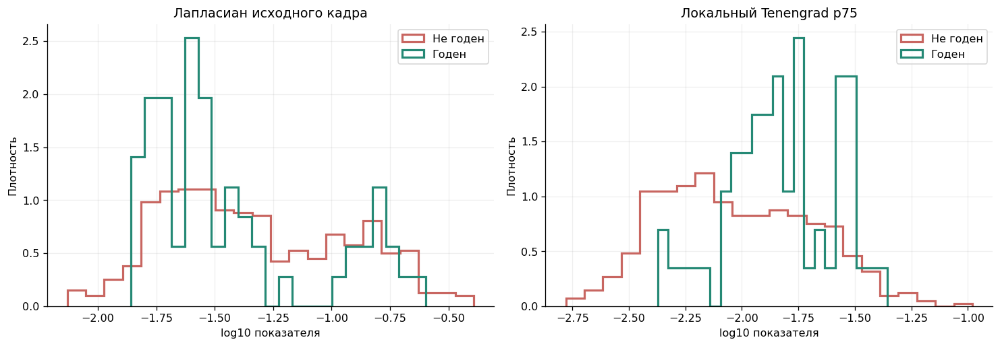

,auroc,ci95
laplacian_raw,0.412365,"[0.3324090674362246, 0.5034772999467924]"
laplacian_smooth,0.478516,"[0.4006646205597509, 0.5619226418974499]"
tenengrad_smooth,0.664914,"[0.5989641919091636, 0.7312210689122384]"
local_tenengrad_p75,0.689925,"[0.6259466241360978, 0.7567052217259986]"


In [8]:
fig,axes=plt.subplots(1,2,figsize=(13,4.6))
for ax,feature,title in zip(axes,['laplacian_raw','local_tenengrad_p75'],['Лапласиан исходного кадра','Локальный Tenengrad p75']):
    for truth,label,color in [(0,'Не годен','#c86661'),(1,'Годен','#258975')]:
        values=np.log10(np.maximum(clear.loc[clear.truth==truth,feature],1e-12))
        ax.hist(values,bins=22,density=True,histtype='step',linewidth=2,label=label,color=color)
    ax.set(xlabel='log10 показателя',ylabel='Плотность',title=title);ax.legend();ax.grid(alpha=.2)
fig.tight_layout();showfig(fig)
display(pd.DataFrame(report['raw_feature_auc']).T)

Здесь направление признака зафиксировано: больше → лучше. Расчёт сделан на 565 согласованных кадрах. Старые цифры 0,427 / 0,470 / 0,644 / 0,666 относились к другой выборке — 790 исходных определённых меток. Смена выборки и разметки не означает улучшение самого показателя.

AUROC модели по одному признаку может отличаться от AUROC исходного показателя: знак связи и калибровка выбирались на внутренних пациентах, а прогнозы получены пятью разными внешними моделями.

### 3.2. Почти одинаковый Tenengrad — разные метки

Алгоритм ниже находит хорошую и плохую фотографию **разных пациентов** с минимальной разницей `log10(local_tenengrad_p75)`. Сравни их полное поле и подписи. Близкое среднее число не фиксирует, где именно есть резкость и какие структуры её создают.

Такая пара — иллюстрация неоднозначности одного скалярного признака. Частоту ошибок оценивают по всей выборке, а не по этой выбранной паре.

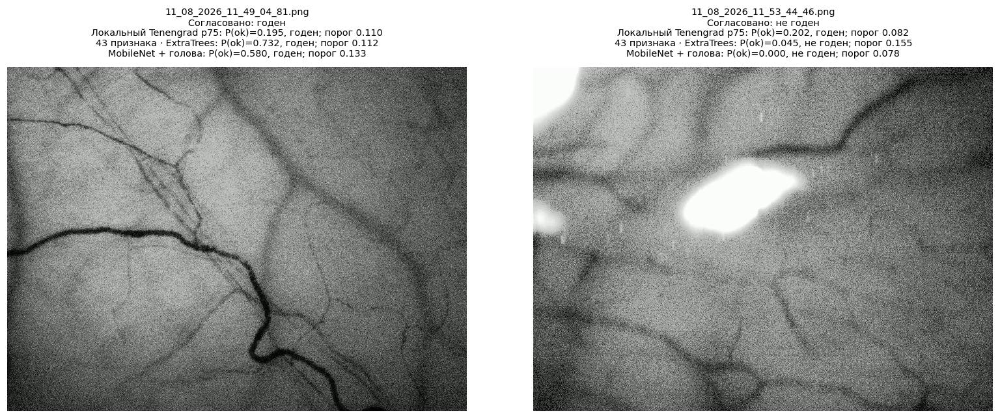

,"консенсус: 1=годен, 0=нет, -1=спорно",human,assistant,patient,fold,laplacian_raw,laplacian_smooth,tenengrad_smooth,local_tenengrad_p75,logistic_basic_p,trees_basic_p,logistic_extended_p,trees_extended_p,neural_p
file,,,,,,,,,,,,,,
11_08_2026_11_49_04_81.png,1,ok,ok,14387,2,0.123292,0.000729,0.023174,0.028126,0.171616,0.243170,0.718776,0.731566,0.579619
11_08_2026_11_53_44_46.png,0,not_ok,not_ok,14388,0,0.174321,0.000989,0.024915,0.028126,0.092663,0.404235,0.001224,0.045344,0.000360


Разница log10 локального Tenengrad: 4.93975604176633e-06


In [9]:
good=clear[clear.truth==1];bad=clear[clear.truth==0]
distance=np.abs(np.log10(good.local_tenengrad_p75.to_numpy())[:,None]-np.log10(bad.local_tenengrad_p75.to_numpy())[None,:])
distance[good.patient.to_numpy()[:,None]==bad.patient.to_numpy()[None,:]]=np.inf
i,j=np.unravel_index(np.argmin(distance),distance.shape)
near_pair=[good.index[i],bad.index[j]]
show_photos(near_pair,models=('single_local_tenengrad_p75','trees_extended','neural'))
photo_table(near_pair)
print('Разница log10 локального Tenengrad:',float(distance[i,j]))

### 3.3. Все три ложных допуска ExtraTrees в строгом режиме

Показаны **все**, а не только самые заметные ошибки этого отбора.

- `12_08_2026_11_41_34_76.png`: часть сети справа чётче, чем центральные и левые продолжения. Локально сильные границы могут сосуществовать с частичной расфокусировкой.
- `14_08_2026_12_19_54_165.png`: верхняя и центральная сеть различима лучше нижних продолжений. Несмотря на метку `not_ok`, обе модели дают высокую вероятность.
- `12_08_2026_12_36_05_6.png`: заметны направленные полосы и смазывание, чёткой основной сосудистой сети не видно. ExtraTrees даёт высокую оценку, нейросеть — низкую.

Предположение, что направленная текстура обманула численные признаки, правдоподобно для третьего кадра. Это визуальная гипотеза, а не установленное объяснение внутренней логики модели.

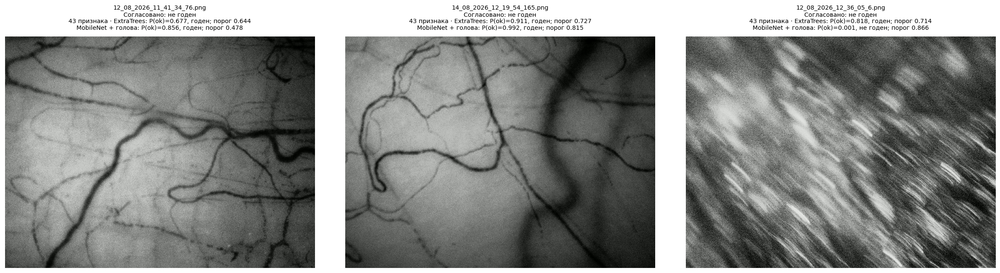

,"консенсус: 1=годен, 0=нет, -1=спорно",human,assistant,patient,fold,laplacian_raw,laplacian_smooth,tenengrad_smooth,local_tenengrad_p75,logistic_basic_p,trees_basic_p,logistic_extended_p,trees_extended_p,neural_p
file,,,,,,,,,,,,,,
12_08_2026_11_41_34_76.png,0,not_ok,not_ok,14407,4,0.036284,0.000223,0.011717,0.014738,0.298000,0.436764,0.591967,0.676883,0.856309
14_08_2026_12_19_54_165.png,0,not_ok,not_ok,14450,1,0.021508,0.000140,0.009900,0.015033,0.531054,0.700839,0.732031,0.911459,0.991713
12_08_2026_12_36_05_6.png,0,not_ok,not_ok,14411,2,0.111263,0.000758,0.035077,0.049496,0.538773,0.249112,0.957761,0.818476,0.000796


In [10]:
tree_errors=clear.index[(clear.truth==0)&clear.trees_extended_precise].tolist()
assert len(tree_errors)==3
show_photos(tree_errors,mode='precise',columns=3)
photo_table(tree_errors)

### 3.4. Локальный фокус по сетке: где теряется информация

Карта ниже — Tenengrad после σ=1 по тем же 16 участкам, что использовались в признаках. Общая шкала одинакова для двух кадров. Она показывает энергию перепадов яркости, **не вероятность качества и не сосудистую маску**. Сетка не умеет самостоятельно отличить глубокий фон от основной сети, а полосы смазывания — от чёткой ветви.

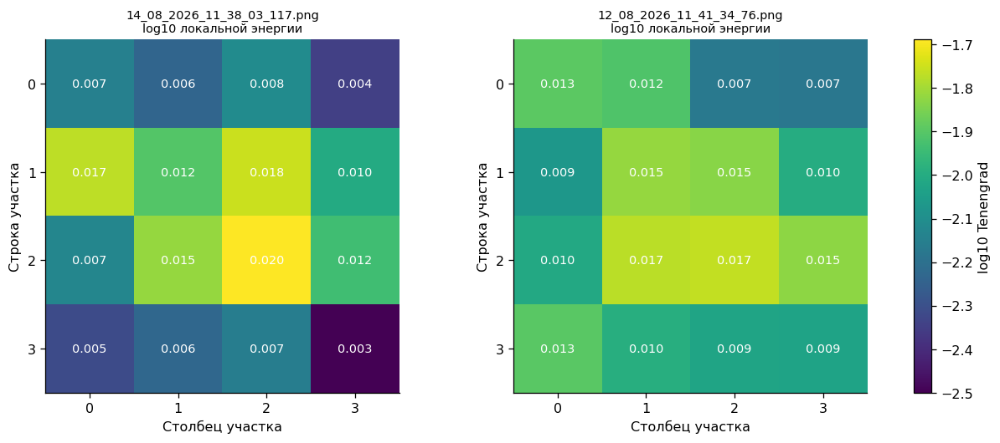

In [11]:
import cv2
from focus_classifier.features import gradient,tiles
map_files=[examples['good'][0],tree_errors[0]]
maps=[]
for file in map_files:
    a=cv2.imdecode(np.frombuffer(image_path(file).read_bytes(),np.uint8),cv2.IMREAD_GRAYSCALE).astype(np.float32)/255
    smooth=cv2.GaussianBlur(a,(0,0),1.0)
    maps.append(np.array([t.mean() for t in tiles(gradient(smooth)[2])]).reshape(4,4))
vmin=min(np.log10(m).min() for m in maps);vmax=max(np.log10(m).max() for m in maps)
fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
for ax,file,m in zip(axes,map_files,maps):
    image=ax.imshow(np.log10(m),vmin=vmin,vmax=vmax,cmap='viridis')
    ax.set_title(file+chr(10)+'log10 локальной энергии',fontsize=9)
    ax.set(xticks=range(4),yticks=range(4),xlabel='Столбец участка',ylabel='Строка участка')
    for i in range(4):
        for j in range(4):ax.text(j,i,f'{m[i,j]:.3f}',ha='center',va='center',color='white',fontsize=9)
fig.colorbar(image,ax=list(axes),label='log10 Tenengrad');showfig(fig)

### 3.5. Все ложные допуски нейросети в строгом режиме

Это полный список из семи кадров с согласованной меткой `not_ok`, которые приняла нейросеть. Сравни с предыдущими тремя: ошибка одной модели не обязательно является ошибкой другой. Ниже подписи показывают именно строгий режим.

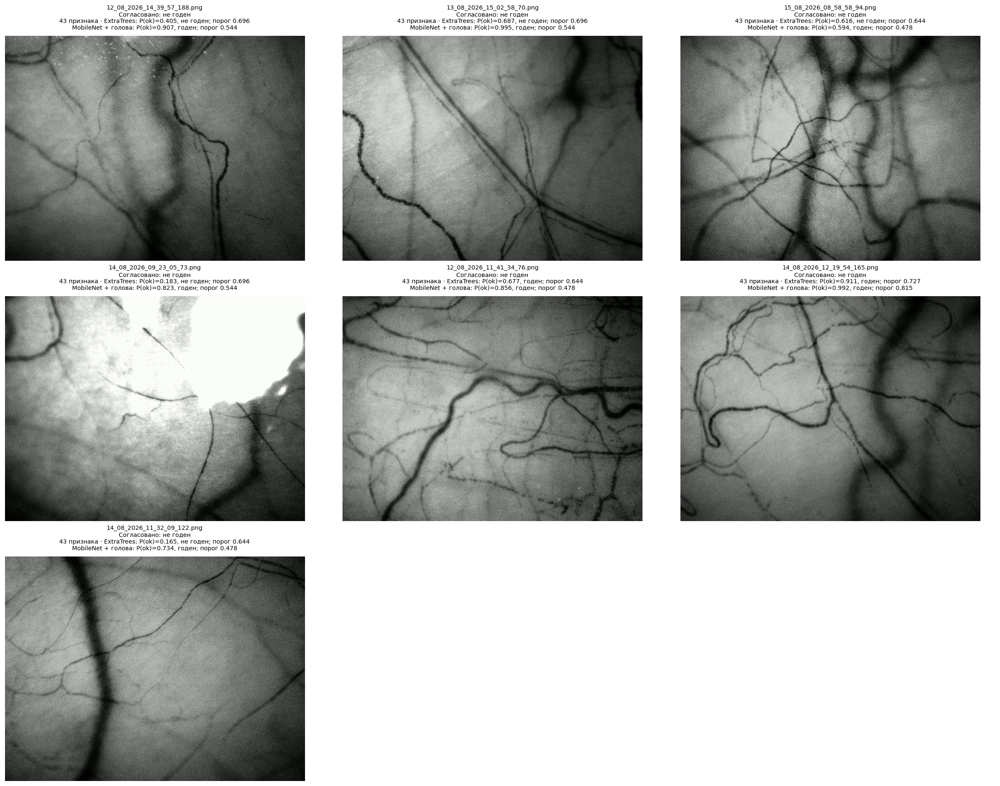

,"консенсус: 1=годен, 0=нет, -1=спорно",human,assistant,patient,fold,laplacian_raw,laplacian_smooth,tenengrad_smooth,local_tenengrad_p75,logistic_basic_p,trees_basic_p,logistic_extended_p,trees_extended_p,neural_p
file,,,,,,,,,,,,,,
12_08_2026_14_39_57_188.png,0,not_ok,not_ok,14415,0,0.022576,0.000151,0.007452,0.011144,0.275014,0.293391,0.674937,0.404680,0.907404
13_08_2026_15_02_58_70.png,0,not_ok,not_ok,14433,0,0.017102,0.000124,0.008594,0.010921,0.486976,0.646909,0.744768,0.687069,0.994756
15_08_2026_08_58_58_94.png,0,not_ok,not_ok,14459,4,0.047234,0.000294,0.014097,0.016662,0.274300,0.435378,0.443417,0.616411,0.594230
14_08_2026_09_23_05_73.png,0,not_ok,not_ok,14437,0,0.023690,0.000174,0.010865,0.013081,0.468249,0.718719,0.365127,0.183163,0.822901
12_08_2026_11_41_34_76.png,0,not_ok,not_ok,14407,4,0.036284,0.000223,0.011717,0.014738,0.298000,0.436764,0.591967,0.676883,0.856309
14_08_2026_12_19_54_165.png,0,not_ok,not_ok,14450,1,0.021508,0.000140,0.009900,0.015033,0.531054,0.700839,0.732031,0.911459,0.991713
14_08_2026_11_32_09_122.png,0,not_ok,not_ok,14445,4,0.038305,0.000230,0.008548,0.009873,0.084538,0.223753,0.194975,0.165045,0.733738


In [12]:
neural_errors=clear.index[(clear.truth==0)&clear.neural_precise].tolist()
assert len(neural_errors)==7
show_photos(neural_errors,mode='precise',columns=3)
photo_table(neural_errors)

### 3.6. Все три хороших кадра, потерянные нейросетью в обычном режиме

Один из примеров — `12_08_2026_11_41_10_102.png`: диагональные тонкие сосуды основной сети различимы поверх широкой размытой фоновой структуры. По согласованному критерию глубокий размытый фон допустим, однако модель дала низкую оценку.

Это возможный тип ошибки, который необходимо проверять на новых пациентах: наличие глубокого фона не должно автоматически приводить к отбрасыванию. По одному примеру нельзя доказать, что именно фон вызвал решение модели.

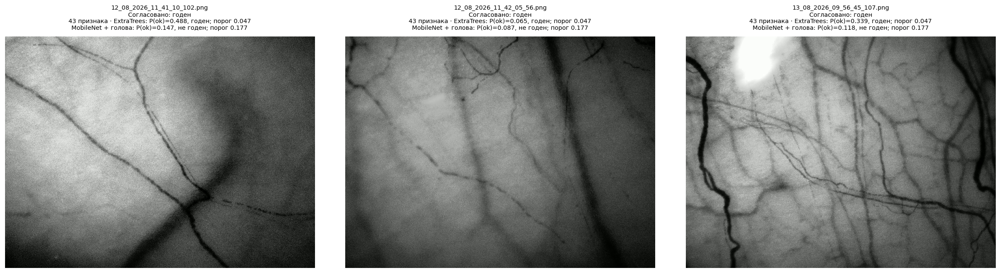

,"консенсус: 1=годен, 0=нет, -1=спорно",human,assistant,patient,fold,laplacian_raw,laplacian_smooth,tenengrad_smooth,local_tenengrad_p75,logistic_basic_p,trees_basic_p,logistic_extended_p,trees_extended_p,neural_p
file,,,,,,,,,,,,,,
12_08_2026_11_41_10_102.png,1,ok,ok,14407,4,0.039397,0.000248,0.009874,0.013768,0.168942,0.261732,0.398651,0.488206,0.147279
12_08_2026_11_42_05_56.png,1,ok,ok,14407,4,0.017335,0.000108,0.004323,0.005400,0.059056,0.031704,0.080890,0.065251,0.086605
13_08_2026_09_56_45_107.png,1,ok,ok,14420,4,0.017613,0.000139,0.011314,0.014994,0.719406,0.618860,0.273286,0.338612,0.118058


In [13]:
missed=clear.index[(clear.truth==1)&~clear.neural_balanced].tolist()
assert len(missed)==3
show_photos(missed,columns=3)
photo_table(missed)

### 3.7. Один и тот же участок без сглаживания и улучшения контраста

Показаны центральные участки 320×320 исходных кадров из примера с шумом и одного частично резкого кадра. Координаты одинаковы, для рисунка использована ближайшая интерполяция. Поле обрезки не подбиралось по результату модели. Такая иллюстрация помогает различать зернистость и протяжённые границы, но качество всего кадра по одному участку не устанавливает.

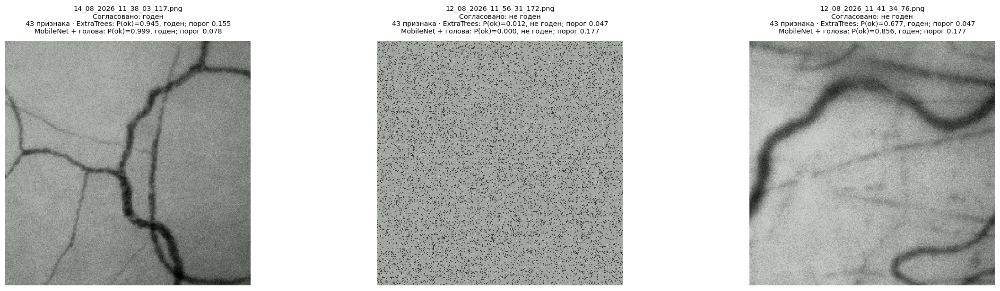

In [14]:
show_photos(noise_pair+[tree_errors[0]],crop=(352,224,320,320),columns=3)

### 3.8. Когда модели расходятся и когда нет согласованного ответа

Сначала показаны четыре согласованных кадра, у которых обычные решения ExtraTrees и нейросети различаются. Кадры упорядочены по максимальной разнице их вероятностей. Это полезные кандидаты для разбора различий, а не новая тестовая выборка.

Затем — четыре кадра без согласованного бинарного эталона. Для них можно сравнить прогнозы с обеими оценками разметчиков, но нельзя автоматически объявить модель правильной или ошибочной.

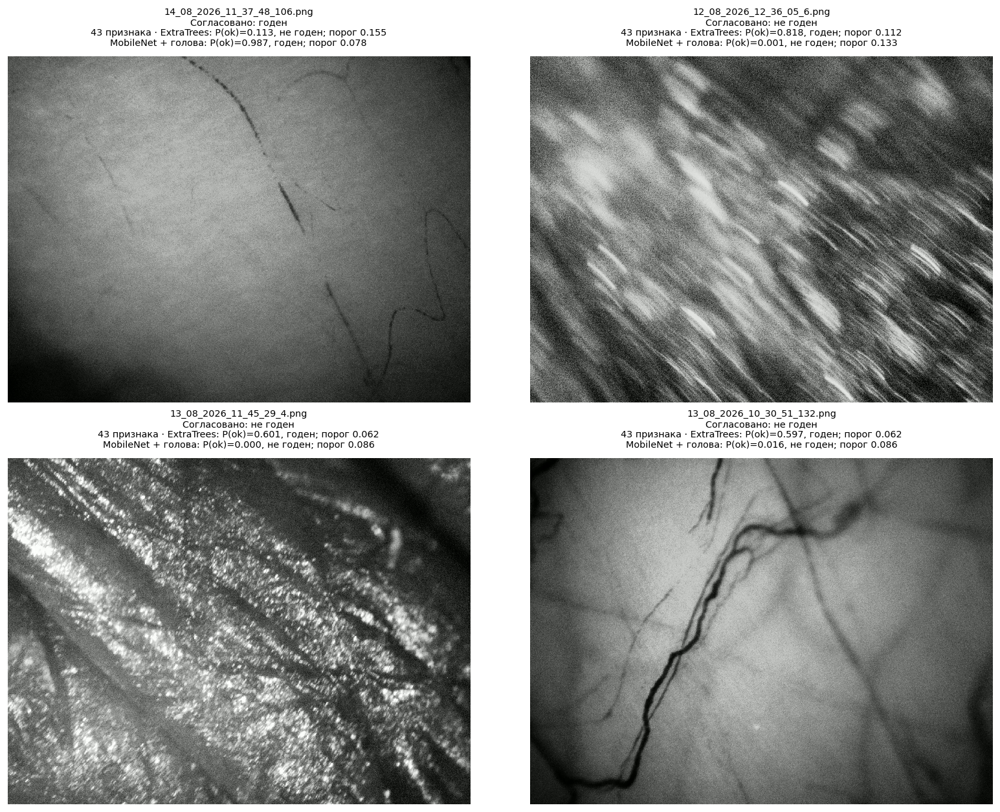

,"консенсус: 1=годен, 0=нет, -1=спорно",human,assistant,patient,fold,laplacian_raw,laplacian_smooth,tenengrad_smooth,local_tenengrad_p75,logistic_basic_p,trees_basic_p,logistic_extended_p,trees_extended_p,neural_p
file,,,,,,,,,,,,,,
14_08_2026_11_37_48_106.png,1,ok,ok,14446,0,0.022985,0.000142,0.004767,0.005063,0.028984,0.007316,0.065445,0.113235,0.986782
12_08_2026_12_36_05_6.png,0,not_ok,not_ok,14411,2,0.111263,0.000758,0.035077,0.049496,0.538773,0.249112,0.957761,0.818476,0.000796
13_08_2026_11_45_29_4.png,0,not_ok,not_ok,14425,1,0.040722,0.000804,0.075710,0.104717,0.996946,0.291722,0.931835,0.600655,0.000227
13_08_2026_10_30_51_132.png,0,not_ok,not_ok,15198,1,0.026096,0.000163,0.008926,0.008782,0.190041,0.471215,0.932875,0.597169,0.015541


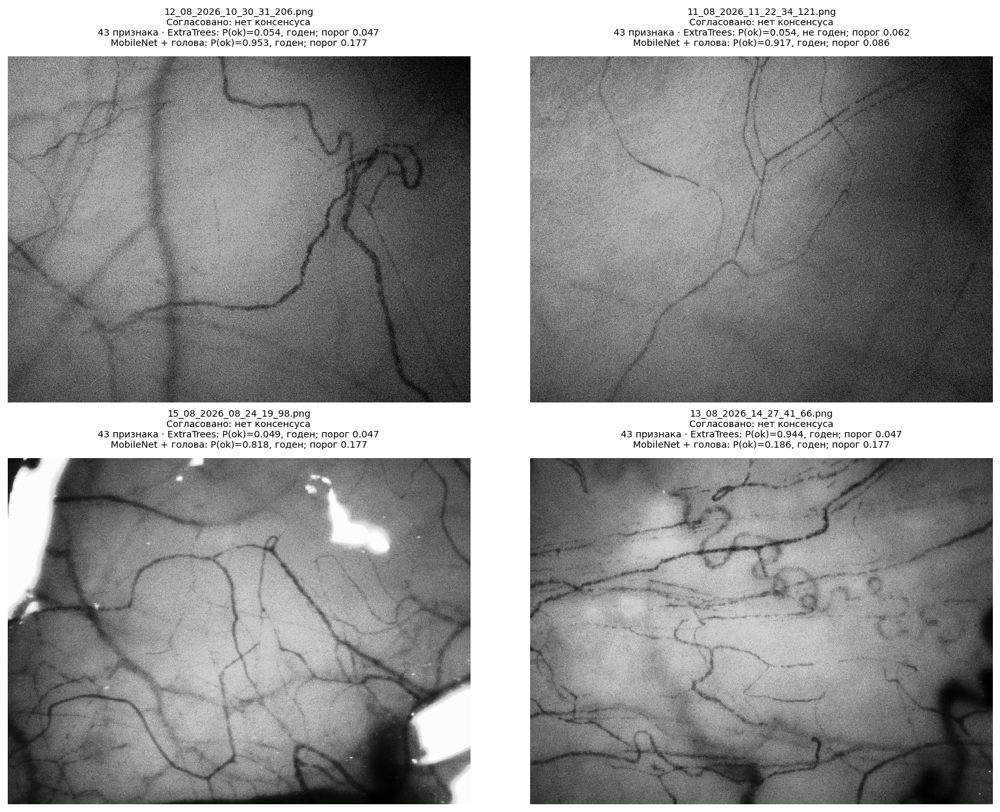

,human,assistant,trees_extended_p,neural_p,comment
file,,,,,
12_08_2026_10_30_31_206.png,not_ok,uncertain,0.053710,0.953300,"Правая сеть и левая верхняя петля различимы, н..."
11_08_2026_11_22_34_121.png,not_ok,uncertain,0.053588,0.917367,"Тонкая сеть прослеживается, но слабый контраст..."
15_08_2026_08_24_19_98.png,ok,uncertain,0.048723,0.817715,
13_08_2026_14_27_41_66.png,uncertain,not_ok,0.943517,0.186332,"Часть мелких ветвей чёткая, но центральные и п..."


In [15]:
different=clear[clear.trees_extended_balanced != clear.neural_balanced].copy()
different['gap']=(different.trees_extended_p-different.neural_p).abs()
different_files=different.sort_values('gap',ascending=False).head(4).index.tolist()
show_photos(different_files)
photo_table(different_files)
unresolved=df[df.truth<0].copy()
unresolved['gap']=(unresolved.trees_extended_p-unresolved.neural_p).abs()
unresolved_files=unresolved.sort_values('gap',ascending=False).head(4).index.tolist()
show_photos(unresolved_files)
display(df.loc[unresolved_files,['human','assistant','trees_extended_p','neural_p','comment']])

## 4. Калибровка: что означает вероятность модели

Для каждого из десяти интервалов вероятности считаем:

`ECE = сумма [(число кадров в интервале / N) × |средняя вероятность − наблюдаемая доля|]`.

Для **ECE класса ok** сравниваются `P(ok)` и доля хороших. Для **top-label ECE** — уверенность в выбранном классе и доля правильных ответов. Это разные проверки, поэтому сохраняем обе. Sigmoid-калибровка обучалась только внутри внешней обучающей части.

На reliability diagram идеал — диагональ. Малые по числу кадров интервалы могут сильно отклоняться случайно. В таблице есть также Brier и log loss. Brier здесь — среднее `(P(ok)−y)²` для бинарного случая.

,ECE ok до,ECE ok после,ECE top после,Brier,Log loss
Модель,,,,,
4 признака · LR,0.2108,0.0406,0.0302,0.0750,0.2551
4 признака · ExtraTrees,0.1630,0.0195,0.0195,0.0689,0.2362
43 признака · LR,0.0794,0.0160,0.0117,0.0494,0.1584
43 признака · ExtraTrees,0.0636,0.0203,0.0135,0.0459,0.1502
MobileNet + голова,0.0288,0.0231,0.0137,0.0313,0.1034


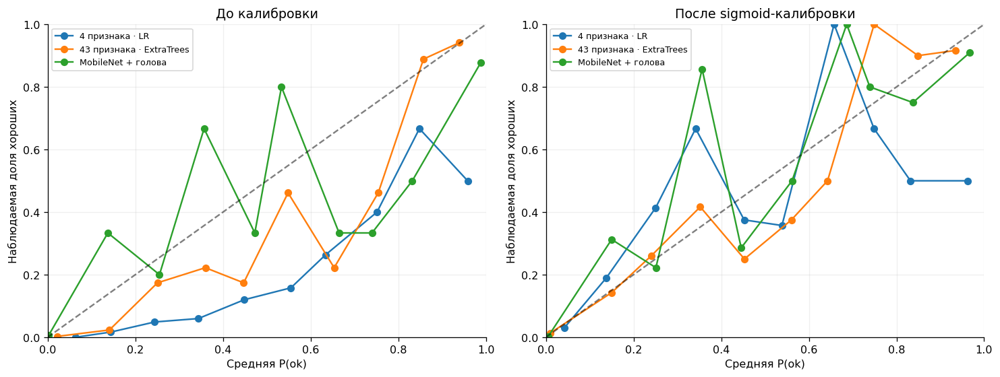

,left,right,count,mean_probability,observed_frequency
380,0.0,0.1,471,0.004966,0.002123
381,0.1,0.2,16,0.149996,0.312500
382,0.2,0.3,9,0.250959,0.222222
383,0.3,0.4,7,0.356387,0.857143
384,0.4,0.5,7,0.445621,0.285714
385,0.5,0.6,6,0.561620,0.500000
386,0.6,0.7,3,0.686359,1.000000
387,0.7,0.8,5,0.739149,0.800000
388,0.8,0.9,8,0.837440,0.750000
389,0.9,1.0,33,0.966629,0.909091


In [16]:
calibration_rows=[]
for model in MAIN:
    m=report['models'][model];c,r=m['calibrated'],m['raw']
    calibration_rows.append({'Модель':SHORT[model], 'ECE ok до':r['ece_ok']['10'], 'ECE ok после':c['ece_ok']['10'],
                             'ECE top после':c['ece_top']['10'], 'Brier':c['brier'], 'Log loss':c['log_loss']})
display(pd.DataFrame(calibration_rows).set_index('Модель').round(4))
bin_data=pd.read_csv(ART/'reliability_bins.csv')
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,variant,title in zip(axes,['raw','calibrated'],['До калибровки','После sigmoid-калибровки']):
    for model in ['logistic_basic','trees_extended','neural']:
        b=bin_data[(bin_data.model==model)&(bin_data.variant==variant)&(bin_data.kind=='ok')&(bin_data['count']>0)]
        ax.plot(b.mean_probability,b.observed_frequency,'o-',label=SHORT[model])
    ax.plot([0,1],[0,1],'k--',alpha=.5)
    ax.set(xlim=(0,1),ylim=(0,1),xlabel='Средняя P(ok)',ylabel='Наблюдаемая доля хороших',title=title)
    ax.legend(fontsize=8);ax.grid(alpha=.2)
fig.tight_layout();showfig(fig)
display(bin_data[(bin_data.model=='neural')&(bin_data.variant=='calibrated')&(bin_data.kind=='ok')][['left','right','count','mean_probability','observed_frequency']])

**Почему одного ECE недостаточно.** Константная вероятность, примерно равная доле хороших, здесь имеет ECE почти ноль и всё равно не помогает отбирать фотографии. Поэтому маленький ECE не является условием «классификатор работает».

При сильном дисбалансе общая калибровка также может скрывать ошибки в редких высоких вероятностях. Для выбора кадров нужны число ложных допусков, precision, recall и их неопределённость.

In [17]:
print('ECE ok константной вероятности:',report['models']['constant']['calibrated']['ece_ok']['10'])
intervals=[]
for model in ['trees_extended','neural']:
    m=report['models'][model]
    intervals.append({'Модель':SHORT[model], 'Precision строго':m['precise']['precision_ok'],
                      '95% интервал precision строго':m['precise']['ci95']['precision_ok'],
                      'Recall строго':m['precise']['recall_ok'],
                      '95% интервал recall строго':m['precise']['ci95']['recall_ok'],
                      '95% интервал ECE ok':m['ci95']['ece_ok_10']})
display(pd.DataFrame(intervals).set_index('Модель'))

ECE ok константной вероятности: 8.54001035414248e-05


,Precision строго,95% интервал precision строго,Recall строго,95% интервал recall строго,95% интервал ECE ok
Модель,,,,,
43 признака · ExtraTrees,0.906250,"[0.8064292114695341, 1.0]",0.467742,"[0.3384615384615385, 0.6071603641456582]","[0.018059369333603675, 0.04522115119015811]"
MobileNet + голова,0.829268,"[0.7241379310344828, 0.925]",0.548387,"[0.4126750700280112, 0.6818560606060605]","[0.016865884363305366, 0.04196619551582935]"


## 5. Скорость: отдельно чтение PNG и анализ кадра

Замер выполнен на CPU при batch=1, после прогрева, по 50 изображениям на модель. Загрузка весов не входит во время одного кадра. OpenCV использует один поток, PyTorch — два. Файловый кэш ОС мог быть прогрет; замер отражает эту Python-реализацию и текущую нагрузку компьютера.

**p50** — медиана, **p95** — время, в которое уложились примерно 95% измерений. Анализ готового массива ближе к сценарию кадра из камеры, чем полный путь чтения PNG. Полученные значения не являются гарантией стабильной частоты кадров в видеопотоке.

Процессор: Intel(R) Core(TM) i5-9300H CPU @ 2.40GHz


,"PNG → решение p50, мс","PNG → решение p95, мс","Анализ без декодирования p50, мс","Только классификатор p50, мс",Кадров/с последовательно
Модель,,,,,
4 признака · LR,63.5,140.8,31.3,1.0,13.4
4 признака · ExtraTrees,73.2,146.7,49.0,20.6,11.5
43 признака · LR,232.2,418.6,208.2,0.9,3.8
43 признака · ExtraTrees,203.0,303.0,179.9,16.9,4.7
MobileNet + голова,59.2,90.9,32.0,0.9,9.3


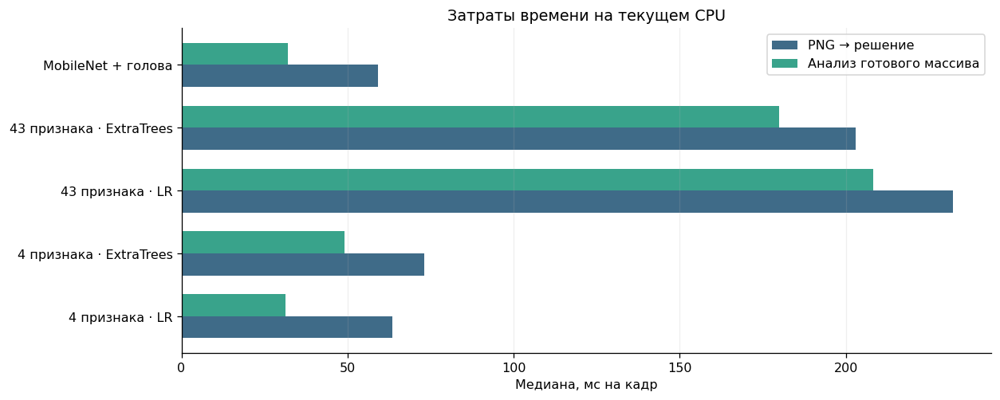

In [18]:
print('Процессор:',speed.get('processor_model',speed['processor']))
speed_table=pd.DataFrame([{ 'Модель':SHORT[m], 'PNG → решение p50, мс':s['end_to_end_ms_p50'],
                           'PNG → решение p95, мс':s['end_to_end_ms_p95'],
                           'Анализ без декодирования p50, мс':s['analysis_only_ms_p50'],
                           'Только классификатор p50, мс':s['head_only_ms_p50'],
                           'Кадров/с последовательно':s['throughput_sequential_fps']}
                          for m,s in speed['models'].items()]).set_index('Модель')
display(speed_table.round(1))
fig,ax=plt.subplots(figsize=(11,4.5))
positions=np.arange(len(MAIN));width=.35
ax.barh(positions-width/2,[speed['models'][m]['end_to_end_ms_p50'] for m in MAIN],height=width,label='PNG → решение',color='#3f6b88')
ax.barh(positions+width/2,[speed['models'][m]['analysis_only_ms_p50'] for m in MAIN],height=width,label='Анализ готового массива',color='#39a38b')
ax.set(yticks=positions,yticklabels=[SHORT[m] for m in MAIN],xlabel='Медиана, мс на кадр',title='Затраты времени на текущем CPU')
ax.grid(axis='x',alpha=.2);ax.legend();fig.tight_layout();showfig(fig)

43 численных признака требуют нескольких сглаживаний, процентилей и локальных статистик на исходном размере. Поэтому такой путь может оказаться медленнее небольшой сети, работающей с уменьшенным кадром. При этом уменьшение кадра может терять мелкие детали, а фиксированный backbone проверяет только один конкретный нейросетевой вариант.

По этому эксперименту нельзя утверждать, что любые численные признаки медленнее нейросети или что любая нейросеть будет лучше. Сравниваются конкретные реализации, разрешения и пороги.

## 6. Свой просмотр любых кадров

Измени параметры следующей ячейки и запусти её снова:

- `MODEL`: `logistic_basic`, `trees_basic`, `logistic_extended`, `trees_extended`, `neural` или любой ключ из `NAMES`.
- `MODE`: `balanced` или `precise`.
- `CATEGORY`: `accepted`, `rejected`, `false_accept`, `false_reject`, `different`, `all`.
- `POOL`: `consensus`, `unresolved`, `all`.
- `N` и `OFFSET`: размер страницы и начало просмотра.
- `MANUAL_THRESHOLD`: `None` для сохранённого порога или число от 0 до 1.

Ручной порог исследует уже известные результаты. Если подобрать его здесь, качество нового правила потребуется проверить на новых пациентах.

В полном отборе 32 кадров; показаны 0–5.


,truth,human,assistant,trees_extended_p
file,,,,
13_08_2026_12_44_41_88.png,1,ok,ok,0.978842
14_08_2026_13_46_46_137.png,1,ok,ok,0.951121
14_08_2026_11_38_03_117.png,1,ok,ok,0.944941
12_08_2026_15_21_48_166.png,1,ok,ok,0.944041
13_08_2026_08_04_30_192.png,1,ok,ok,0.940875
12_08_2026_13_59_09_177.png,1,ok,ok,0.934074
14_08_2026_11_46_46_150.png,1,ok,ok,0.931923
13_08_2026_10_19_02_210.png,1,ok,ok,0.930866
14_08_2026_11_45_58_90.png,1,ok,ok,0.919466


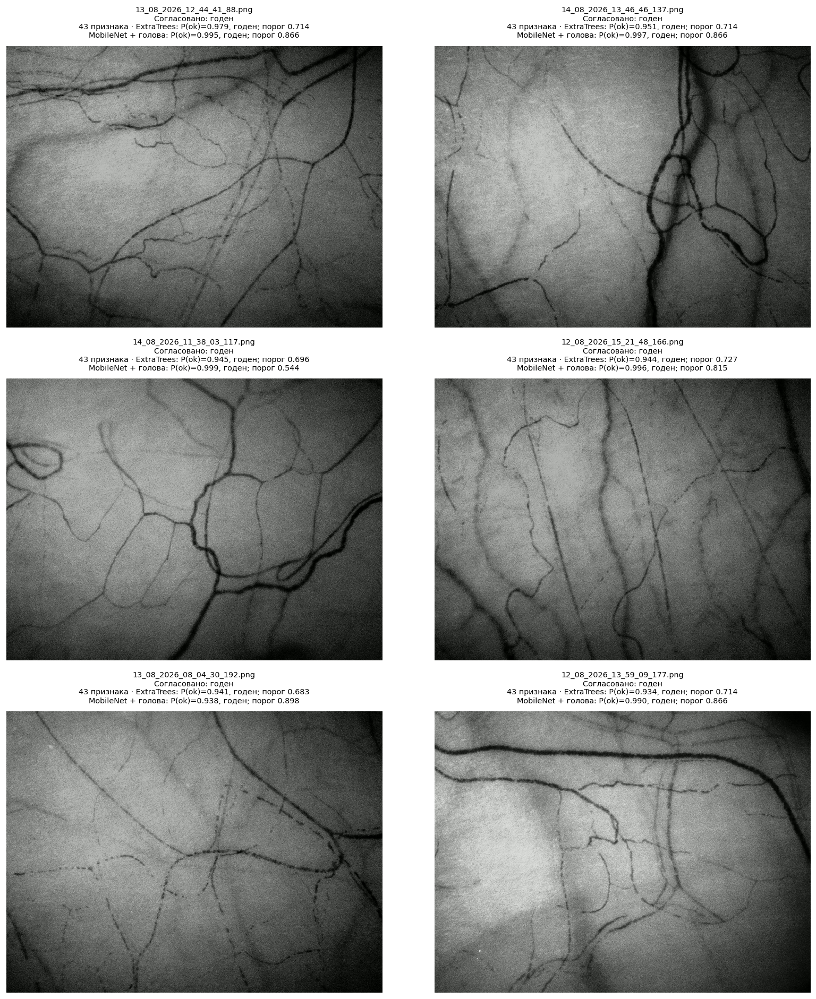

In [19]:
MODEL='trees_extended'
MODE='precise'
CATEGORY='accepted'
POOL='consensus'
N=6
OFFSET=0
MANUAL_THRESHOLD=None

selected_files,selection=pick(MODEL,MODE,CATEGORY,n=N,offset=OFFSET,pool=POOL,threshold=MANUAL_THRESHOLD)
print(f'В полном отборе {len(selection)} кадров; показаны {OFFSET}–{OFFSET+len(selected_files)-1}.')
display(selection[['truth','human','assistant',MODEL+'_p']].head(20))
show_photos(selected_files,models=(MODEL,'neural') if MODEL!='neural' else ('neural','trees_extended'),mode=MODE,manual_threshold=MANUAL_THRESHOLD)
if MANUAL_THRESHOLD is not None:
    print('Фильтр и подписи используют ручной порог. Решения:')
    display(pd.DataFrame({'P(ok)':df.loc[selected_files,MODEL+'_p'],
                          'Решение при ручном пороге':accepted(MODEL,MODE,MANUAL_THRESHOLD).loc[selected_files]}))

### Две любые фотографии, одинаковый участок или полный размер

Подставь имена из таблиц выше. Для небольших сосудов можно выбрать общий участок `(x, y, ширина, высота)`. Для исходного кадра 1:1 есть отдельная команда `DisplayImage(filename=...)`. Увеличение браузера масштабирует отображение, но не добавляет деталей.

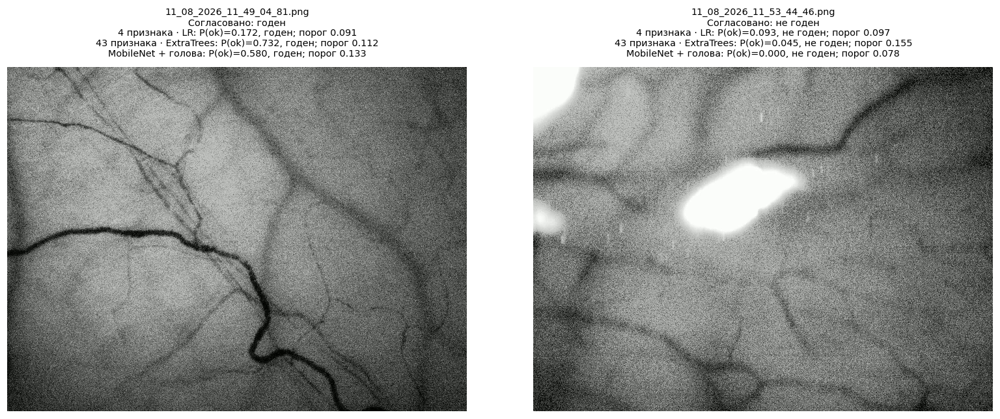

,"консенсус: 1=годен, 0=нет, -1=спорно",human,assistant,patient,fold,laplacian_raw,laplacian_smooth,tenengrad_smooth,local_tenengrad_p75,logistic_basic_p,trees_basic_p,logistic_extended_p,trees_extended_p,neural_p
file,,,,,,,,,,,,,,
11_08_2026_11_49_04_81.png,1,ok,ok,14387,2,0.123292,0.000729,0.023174,0.028126,0.171616,0.243170,0.718776,0.731566,0.579619
11_08_2026_11_53_44_46.png,0,not_ok,not_ok,14388,0,0.174321,0.000989,0.024915,0.028126,0.092663,0.404235,0.001224,0.045344,0.000360


In [20]:
FILES_TO_COMPARE = near_pair
CROP = None  # Например: (352,224,320,320)
show_photos(FILES_TO_COMPARE,models=('logistic_basic','trees_extended','neural'),crop=CROP)
photo_table(FILES_TO_COMPARE)

# Для полного исходного PNG раскомментируй строку:
# display(DisplayImage(filename=str(image_path(FILES_TO_COMPARE[0]))))

### Кривые порога: исследование компромисса

Следующий график пересчитывает решения для единого порога по внешним вероятностям. Он полезен, чтобы увидеть потерю хороших при ужесточении отбора. Он **не заменяет проверку порога**, выбранного после просмотра графика, на новых данных. Не ищи максимум precision без учёта числа принятых кадров.

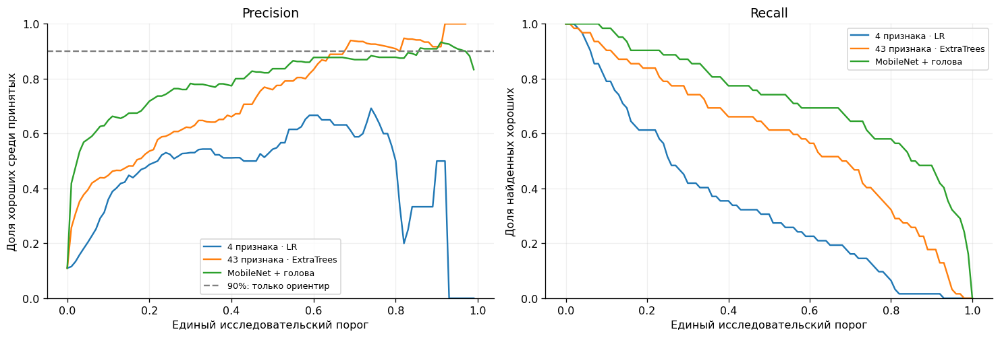

In [21]:
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for model in ['logistic_basic','trees_extended','neural']:
    p=clear[model+'_p'].to_numpy();y=clear.truth.to_numpy()
    thresholds=np.linspace(0,1,101);precisions=[];recalls=[];counts=[]
    for t in thresholds:
        keep=p>=t;counts.append(keep.sum())
        precisions.append(y[keep].mean() if keep.any() else np.nan)
        recalls.append(keep[y==1].mean())
    axes[0].plot(thresholds,precisions,label=SHORT[model])
    axes[1].plot(thresholds,recalls,label=SHORT[model])
axes[0].axhline(.9,color='gray',ls='--',label='90%: только ориентир')
axes[0].set(xlabel='Единый исследовательский порог',ylabel='Доля хороших среди принятых',ylim=(0,1),title='Precision')
axes[1].set(xlabel='Единый исследовательский порог',ylabel='Доля найденных хороших',ylim=(0,1),title='Recall')
for ax in axes:ax.grid(alpha=.2);ax.legend(fontsize=8)
fig.tight_layout();showfig(fig)

### Как сохранить список выбранных фотографий

Эта ячейка оставлена выключенной, чтобы повторный запуск ноутбука не создавал лишних файлов. Для выгрузки поставь `SAVE_SELECTION=True`. Сохраняются имена и оценки; исходные изображения и разметка не меняются.

In [22]:
SAVE_SELECTION=False
if SAVE_SELECTION:
    target=ROOT/'focus_classifier/artifacts/notebook_selection.csv'
    selection.to_csv(target,encoding='utf-8-sig')
    print('Сохранено:',target)
else:
    print('Выгрузка выключена. Основной файл всех оценок: focus_classifier/artifacts/predictions.csv')

Выгрузка выключена. Основной файл всех оценок: focus_classifier/artifacts/predictions.csv


## 7. Выводы и границы применимости

1. **Четырёх исходных показателей недостаточно для чистого автоматического допуска** при испытанном правиле порога. Их объединение лучше отдельных показателей, но не решает задачу полностью.
2. **43 признака дают полезный частичный отбор:** строгая модель приняла 29 из 62 хороших и 3 плохих. Оценка precision 90,6% имеет широкий пациентский интервал примерно 80,6–100%.
3. **Лёгкая нейросеть лучше ранжирует кадры**, но в строгом режиме выбранный порог дал 34 хороших и 7 плохих. При другом требовании к потерям и допускам выбор варианта может измениться.
4. **Скорость нужно измерять:** в текущей реализации нейросеть быстрее расширенного расчёта признаков; четыре признака с линейной моделью дешевле по вычислениям, но заметно слабее по качеству.
5. **ECE не заменяет оценку ошибок.** Почти постоянный бесполезный прогноз может иметь маленький ECE.
6. **Согласованный набор отбирает простые случаи.** Здесь нет независимого финального теста на новой съёмке, эталонных масок сосудов или ошибок измерения диаметра. Эти результаты подтверждают воспроизведение текущих меток, а не точность морфометрии.

Практический следующий шаг: после просмотра ошибок зафиксировать критерий и рабочий порог, затем проверить его на новых пациентах и сопоставить с ошибкой выделения границ сосудов. Размытый глубокий фон стоит отдельно включить в контрольные примеры.

### Файлы и воспроизведение

- Все внешние оценки: `focus_classifier/artifacts/predictions.csv`.
- Все признаки: `features.csv`; подробные метрики и интервалы: `metrics.json`; пациенты частей: `folds.json`.
- Самостоятельный запуск каждой модели и команды обучения: `focus_classifier/README.md`.
- Интерактивный локальный просмотр всех кадров: `start_comparison.cmd` в корне проекта.
- Ноутбук формируется командой `python -m focus_classifier.build_notebook` и выполняется на сохранённых прогнозах без переобучения.

Методические источники: [калибровка scikit-learn](https://scikit-learn.org/stable/modules/calibration.html), [StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html), [MobileNetV3 Small](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.mobilenet_v3_small.html). ECE реализован также в `research/evaluate_calibration.py`.